# Практическое занятие № 9 — базовая и первая обучаемая модели
**Дисциплина:** Технологии искусственного интеллекта — 1 (ТюмГУ)  
**Время:** 90 минут | **Среда:** Python, pandas, scikit-learn, Google Colab  
**Кейс:** прогноз задержки заказа >15 минут на момент оформления.  
**Результат:** воспроизводимые DummyClassifier и LogisticRegression, сравнение на validation и объяснение формул сигмоиды, MSE и Log Loss.  

**Важно:** используйте исходный `orders_dirty.csv` и, если он есть, `split_ids_06.csv` из занятия 6. Впервые обучаем статистики только на train, данные test оставляем закрытыми до занятия 10.

**Адаптация данных:** courier_load отсутствует в исходном CSV и исключён. Сохранён is_weekend из работы 8; это заранее выбранный признак, его подбор по test не проводится. Разбиение и CSV взяты из lb8. Структура ноутбука сохранена.

## Шаг 1. Данные и разбиение (0–15 мин)
Загрузите CSV, проверьте схему, обработку дубликатов и конфликтных меток. Сохраните размеры частей; проверьте, что test не используется при обучении.

In [1]:
# Общая подготовка: одинаковая для практик 7 и 8
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

PATH = Path('orders_dirty.csv')
if not PATH.exists():
    raise FileNotFoundError('Загрузите orders_dirty.csv в файлы Colab или измените PATH.')

from IPython.display import display
import hashlib
source_hash = hashlib.sha256(PATH.read_bytes()).hexdigest()
df_raw = pd.read_csv(PATH, encoding='utf-8-sig')
expected = {'order_id','created_at','distance_km','zone','queue_size',
            'weather','promised_minutes','actual_minutes','late'}
missing_cols = expected - set(df_raw.columns)
assert not missing_cols, f'Отсутствуют необходимые поля: {sorted(missing_cols)}'
print('Сырой набор:', df_raw.shape, '; полные дубликаты:', int(df_raw.duplicated().sum()))

# Удаление полных повторов: не обучаем статистику и не используем test.
df = df_raw.drop_duplicates().copy()
df['late'] = pd.to_numeric(df['late'], errors='coerce')
actual = pd.to_numeric(df['actual_minutes'], errors='coerce')
promised = pd.to_numeric(df['promised_minutes'], errors='coerce')
valid_rule = actual.notna() & promised.notna() & df['late'].isin([0, 1])
conflict = valid_rule & (df['late'] != ((actual - promised) > 15).astype(int))
print('Конфликтных меток (проверяемых):', int(conflict.sum()))
df = df.loc[~conflict & df['late'].isin([0, 1])].copy()
df['late'] = df['late'].astype(int)
# Неполные / конфликтные сведения об идентификаторе требуют отдельного решения.
assert df['order_id'].notna().all(), 'Обнаружены пустые ID заказов.'
assert not df['order_id'].duplicated().any(), 'Есть повторные ID: требуется анализ причины, не случайное удаление.'
print('Рабочая копия:', df.shape)

split_path = Path('split_ids_06.csv')  # Необязательный экспорт из практики № 6
if split_path.exists():
    splits = pd.read_csv(split_path, dtype={'order_id': str})
    assert {'order_id', 'split'} <= set(splits.columns)
    assert set(splits['split']) <= {'train', 'val', 'test'}
    assert splits['order_id'].is_unique
    x = df.assign(order_id=df['order_id'].astype(str)).merge(
        splits[['order_id', 'split']], on='order_id', how='left', validate='one_to_one')
    assert x['split'].notna().all(), 'В split_ids_06.csv перечислены не все рабочие заказы.'
    assert set(splits['order_id']) == set(x['order_id'])
    train = x.loc[x['split'] == 'train'].drop(columns='split').copy()
    val   = x.loc[x['split'] == 'val'].drop(columns='split').copy()
    test  = x.loc[x['split'] == 'test'].drop(columns='split').copy()
else:
    # Воссоздание схемы практики № 6, если файл с IDs не был сохранён.
    train_dev, test = train_test_split(df, test_size=.20, stratify=df['late'], random_state=42)
    train, val = train_test_split(train_dev, test_size=.25,
                                 stratify=train_dev['late'], random_state=42)
    split_export = pd.concat([
       train[['order_id']].assign(split='train'),
       val[['order_id']].assign(split='val'),
       test[['order_id']].assign(split='test')], ignore_index=True)
    split_export.to_csv('split_ids_06.csv', index=False)

sets = [set(a['order_id']) for a in (train, val, test)]
assert len(sets[0]&sets[1]) == len(sets[0]&sets[2]) == len(sets[1]&sets[2]) == 0
assert sets[0]|sets[1]|sets[2] == set(df['order_id'])
assert len(train)+len(val)+len(test) == len(df)
print('train / val / test:', len(train), len(val), len(test))

split_summary = pd.DataFrame([{'subset': label, 'N': len(part),
    'late_n': int(part.late.sum()), 'late_pct': 100*part.late.mean()}
    for label, part in [('train', train), ('val', val)]])
display(split_summary)
split_summary.to_csv('09_split_summary.csv', index=False)
print('Test: только размер и ID; метрики и анализ распределений не выполняются.')

Сырой набор: (600, 10) ; полные дубликаты: 1
Конфликтных меток (проверяемых): 1
Рабочая копия: (598, 10)
train / val / test: 358 120 120


,subset,N,late_n,late_pct
0,train,358,168,46.927374
1,val,120,56,46.666667


Test: только размер и ID; метрики и анализ распределений не выполняются.


## Шаг 2. Производные признаки и полный Pipeline (15–30 мин)
Повторяем преобразования занятия 8. Входят только поля, известные при оформлении заказа. Признаки часа и плановой скорости вычисляются до импутации.

In [2]:
# В Colab функция экспортируется в обычный модуль для безопасного joblib.dump.
# При перезапуске блокнота модуль восстанавливается автоматически.
from pathlib import Path
Path('tyumgu_feature_rules.py').write_text("# Правила преобразования признаков для занятий 7–8\nimport numpy as np\nimport pandas as pd\nNUM_BASE = ['distance_km', 'queue_size',  'promised_minutes']\nCAT = ['zone', 'weather']\nNUM = NUM_BASE + ['hour_sin', 'hour_cos', 'planned_speed_kmh', 'is_weekend']\nINPUT = NUM_BASE + CAT + ['created_at']\n\ndef make_features(X):\n    f = X.loc[:, INPUT].copy()\n    for name in NUM_BASE:\n        f[name] = pd.to_numeric(f[name], errors='coerce')\n    for name in NUM_BASE:\n        f.loc[f[name] < 0, name] = np.nan\n    f.loc[f['promised_minutes'] == 0, 'promised_minutes'] = np.nan\n    for name in CAT:\n        s = f[name].astype('string').str.strip()\n        s = s.mask(s.str.lower().isin(['', 'nan', 'none', 'нет данных', 'неизвестно', 'null']))\n        f[name] = s.astype(object).where(s.notna(), np.nan)\n    time = pd.to_datetime(f['created_at'], errors='coerce')\n    hour = time.dt.hour.astype(float)\n    f['is_weekend'] = (time.dt.dayofweek >= 5).astype(float).where(time.notna(), np.nan)\n    f['hour_sin'] = np.sin(2*np.pi*hour/24)\n    f['hour_cos'] = np.cos(2*np.pi*hour/24)\n    f['planned_speed_kmh'] = 60*f['distance_km']/f['promised_minutes']\n    f['planned_speed_kmh'] = f['planned_speed_kmh'].replace([np.inf, -np.inf], np.nan)\n    return f.drop(columns='created_at')\n", encoding='utf-8')
import importlib
import tyumgu_feature_rules
importlib.reload(tyumgu_feature_rules)
from tyumgu_feature_rules import NUM_BASE, NUM, CAT, INPUT, make_features
F_train, F_val = [make_features(part) for part in (train, val)]
assert set(F_train.columns) == set(NUM + CAT)
assert all(col not in F_train.columns for col in ('late','actual_minutes','order_id'))
print('Матрица до кодирования:', F_train.shape)
print('Числовые столбцы:', NUM, '; категориальные:', CAT)

Матрица до кодирования: (358, 9)
Числовые столбцы: ['distance_km', 'queue_size', 'promised_minutes', 'hour_sin', 'hour_cos', 'planned_speed_kmh', 'is_weekend'] ; категориальные: ['zone', 'weather']


In [3]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

numeric_pipe = Pipeline([
    ('fill', SimpleImputer(strategy='median', add_indicator=True,
                           keep_empty_features=True)),
    ('scale', StandardScaler())
])
cat_pipe = Pipeline([
    ('fill', SimpleImputer(strategy='constant', fill_value='неизвестно')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocess = ColumnTransformer([
    ('num', numeric_pipe, NUM),
    ('cat', cat_pipe, CAT)
], remainder='drop', verbose_feature_names_out=True)

def build_pipeline(classifier):
    return Pipeline([
        ('derive', FunctionTransformer(make_features, validate=False)),
        ('prep', clone(preprocess)),
        ('clf', classifier)
    ])

Xtrain = train[INPUT].copy(); Xval = val[INPUT].copy(); Xtest = test[INPUT].copy()
ytrain = train['late'].astype(int).copy()
yval = val['late'].astype(int).copy()
ytest = test['late'].astype(int).copy()
assert ytrain.nunique() == 2, 'Для обучения необходимы 0 и 1 в train.'
assert {'order_id','late','actual_minutes'}.isdisjoint(Xtrain.columns)
assert set(train['order_id']).isdisjoint(val['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(val['order_id']).isdisjoint(test['order_id'])
print('Обучение:', Xtrain.shape, '| validation:', Xval.shape,
      '| отложенный test:', Xtest.shape)
print('Доли класса late=1 (train / validation):',
      [round(v.mean(), 3) for v in (ytrain,yval)])


Обучение: (358, 6) | validation: (120, 6) | отложенный test: (120, 6)
Доли класса late=1 (train / validation): [np.float64(0.469), np.float64(0.467)]


## Шаг 3. Мини-демонстрация линейной регрессии и MSE (30–42 мин)
Это **отдельный искусственный числовой пример**, не обучение длительности доставки и не источник классификационной метки. Исследуйте, как штрафуются большие ошибки.

y_hat = 3.571 + 1.845 x
MSE=0.984; RMSE=0.992


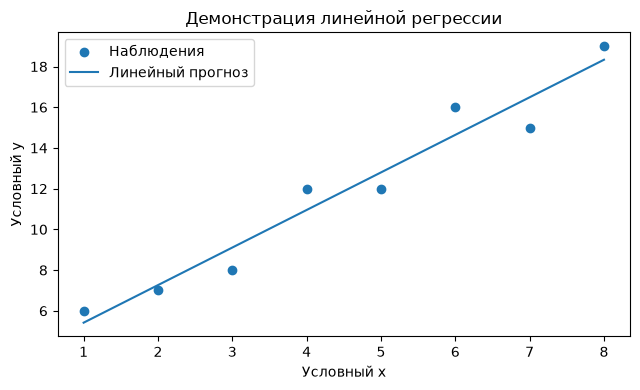

Объект 1: y=6.000000, прогноз=5.416667, ошибка=0.583333, квадрат=0.340278


In [4]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error

x_demo = np.array([1,2,3,4,5,6,7,8], dtype=float).reshape(-1,1)
y_demo = np.array([6,7,8,12,12,16,15,19], dtype=float)
linear = LinearRegression().fit(x_demo, y_demo)
pred_demo = linear.predict(x_demo)
mse = mean_squared_error(y_demo, pred_demo)
rmse = root_mean_squared_error(y_demo, pred_demo)
print(f'y_hat = {linear.intercept_:.3f} + {linear.coef_[0]:.3f} x')
print(f'MSE={mse:.3f}; RMSE={rmse:.3f}')
fig, ax = plt.subplots(figsize=(6.5,4))
ax.scatter(x_demo[:,0],y_demo,label='Наблюдения')
ax.plot(x_demo[:,0],pred_demo,label='Линейный прогноз')
ax.set(title='Демонстрация линейной регрессии', xlabel='Условный x',ylabel='Условный y')
ax.legend(); plt.tight_layout(); plt.savefig('09_linear_demo.png', dpi=160); plt.show()

manual_error = float(y_demo[0] - pred_demo[0])
print(f'Объект 1: y={y_demo[0]:.6f}, прогноз={pred_demo[0]:.6f}, ошибка={manual_error:.6f}, квадрат={manual_error**2:.6f}')
np.testing.assert_allclose(mse, np.mean((y_demo-pred_demo)**2))
np.testing.assert_allclose(rmse, np.sqrt(mse))
pd.DataFrame({'x': x_demo[:,0], 'y': y_demo, 'prediction': pred_demo,
              'error': y_demo-pred_demo, 'squared_error': (y_demo-pred_demo)**2}).to_csv('09_demo_errors.csv', index=False)

## Шаг 4. DummyClassifier: отправная точка (42–55 мин)
Базовая стратегия `prior` оценивает частоту `late=1` в train, а для класса выдаёт наиболее частую метку. Она не использует предикторы для принятия решения. На тесте ничего не вычисляем.

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, log_loss

baseline = build_pipeline(DummyClassifier(strategy='prior'))
baseline.fit(Xtrain, ytrain)
base_pred = baseline.predict(Xval)
base_prob = baseline.predict_proba(Xval)[:, list(baseline.named_steps['clf'].classes_).index(1)]
print('Частота класса 1 в train:',round(ytrain.mean(),4))
print('Первые вероятности baseline:',np.round(base_prob[:10],4))

def metric_row(name, truth, labels, probs):
    return {'Модель':name, 'Accuracy':accuracy_score(truth,labels),
            'Precision':precision_score(truth,labels,zero_division=0),
            'Recall':recall_score(truth,labels,zero_division=0),
            'F1':f1_score(truth,labels,zero_division=0),
            'Balanced accuracy':balanced_accuracy_score(truth,labels),
            'Log Loss':log_loss(truth,probs,labels=[0,1])}

results = [metric_row('Dummy: prior',yval,base_pred,base_prob)]
print(pd.DataFrame(results).round(3).to_string(index=False))


Частота класса 1 в train: 0.4693
Первые вероятности baseline: [0.4693 0.4693 0.4693 0.4693 0.4693 0.4693 0.4693 0.4693 0.4693 0.4693]
      Модель  Accuracy  Precision  Recall  F1  Balanced accuracy  Log Loss
Dummy: prior     0.533        0.0     0.0 0.0                0.5     0.691


## Шаг 5. LogisticRegression: обучение и вероятности (55–75 мин)
Формула: p(y=1|x)=σ(z), где z=β₀+Σβⱼxⱼ, σ(z)=1/(1+e⁻ᶻ). После `fit` используем `predict_proba` только на validation.

,Модель,Accuracy,Precision,Recall,F1,Balanced accuracy,Log Loss,ΔF1
0,Dummy: prior,0.533333,0.000000,0.000000,0.000000,0.500000,0.690937,0.666667
1,"LogReg, threshold=0.50",0.691667,0.672727,0.660714,0.666667,0.689732,0.581789,0.666667


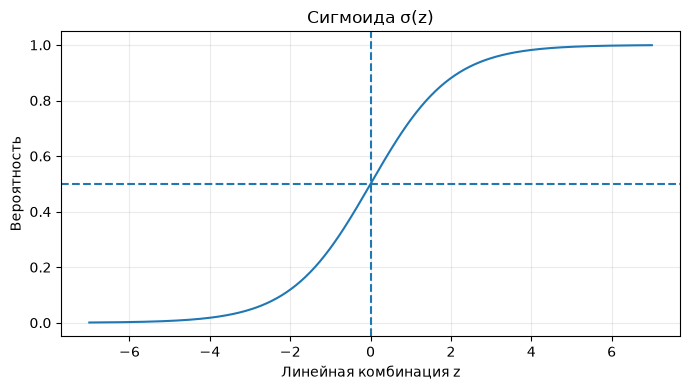

ΔF1 = 0.6666666666666666 ; положительный знак означает преимущество LogReg по F1.


In [6]:
model = build_pipeline(LogisticRegression(C=1.0, max_iter=3000, random_state=42))
model.fit(Xtrain, ytrain)
val_prob = model.predict_proba(Xval)[:, list(model.named_steps['clf'].classes_).index(1)]
val_pred = (val_prob >= .5).astype(int)
results.append(metric_row('LogReg, threshold=0.50', yval, val_pred, val_prob))
compare = pd.DataFrame(results)
compare['ΔF1'] = results[1]['F1'] - results[0]['F1']
display(compare)
compare.to_csv('09_validation_models.csv',index=False)

z = np.linspace(-7,7,350)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(z, 1/(1+np.exp(-z)))
ax.axhline(.5,linestyle='--'); ax.axvline(0,linestyle='--')
ax.set(title='Сигмоида σ(z)',xlabel='Линейная комбинация z',ylabel='Вероятность')
ax.grid(alpha=.25); plt.tight_layout(); plt.savefig('09_sigmoid.png', dpi=160); plt.show()

np.testing.assert_allclose(base_prob, ytrain.mean())
np.testing.assert_allclose(1/(1+np.exp(-model.decision_function(Xval))), val_prob)
manual_logloss = -np.mean(yval*np.log(np.clip(val_prob,1e-15,1-1e-15)) +
                         (1-yval)*np.log(np.clip(1-val_prob,1e-15,1-1e-15)))
np.testing.assert_allclose(manual_logloss, results[1]['Log Loss'])
print('ΔF1 =', results[1]['F1']-results[0]['F1'], '; положительный знак означает преимущество LogReg по F1.')
pd.DataFrame({'order_id': val.order_id, 'late': yval, 'dummy_probability': base_prob,
              'dummy_prediction': base_pred, 'probability': val_prob, 'prediction': val_pred}).to_csv('09_val_predictions.csv', index=False)

## Шаг 6. Параметры и интерпретация (75–85 мин)
Проверяйте признаки, коэффициенты и схему. Коэффициенты относятся к преобразованным столбцам, а не к исходным единицам; корреляция не доказывает причинность.

In [7]:
feature_names = model.named_steps['prep'].get_feature_names_out()
coefs = model.named_steps['clf'].coef_.ravel()
coef_table = pd.DataFrame({'признак_после_преобразования':feature_names,
                           'коэффициент':coefs})
coef_table['модуль'] = coef_table['коэффициент'].abs()
coef_table = coef_table.sort_values('модуль',ascending=False)
display(coef_table.head(12))
coef_table.to_csv('09_coefficients.csv',index=False)
assert np.isfinite(val_prob).all() and (val_prob>=0).all() and (val_prob<=1).all()
assert len(val_prob)==len(yval)
assert 'actual_minutes' not in INPUT and 'late' not in INPUT
# Тестовая часть сознательно не затрагивается до занятия № 10.
print('Проверки вероятностей и схемы: успешно')


import joblib
import json
prep = model.named_steps['prep']
num = prep.named_transformers_['num']
fill = num.named_steps['fill']; scale = num.named_steps['scale']
np.testing.assert_allclose(fill.statistics_, F_train[NUM].median())
np.testing.assert_allclose(scale.mean_, fill.transform(F_train[NUM]).mean(axis=0))
assert len(feature_names) == len(set(feature_names))
assert model.named_steps['clf'].n_iter_.max() < 3000
np.testing.assert_allclose(baseline[:-1].transform(Xval), model[:-1].transform(Xval))
before = joblib.hash(model)
assert model[:-1].transform(Xval).shape == (len(val), len(feature_names))
assert np.isfinite(model[:-1].transform(Xval)).all()
assert before == joblib.hash(model)
pd.DataFrame({'feature': fill.get_feature_names_out(NUM),
    'median': list(fill.statistics_) + [np.nan]*(len(scale.mean_)-len(NUM)),
    'mean': scale.mean_, 'scale': scale.scale_}).to_csv('09_train_parameters.csv', index=False)
joblib.dump(model, '09_model.joblib')
np.testing.assert_allclose(joblib.load('09_model.joblib').predict_proba(Xval)[:,1], val_prob)
summary = {'demo_intercept': float(linear.intercept_), 'demo_slope': float(linear.coef_[0]),
           'mse': float(mse), 'rmse': float(rmse), 'manual_error': manual_error,
           'manual_squared_error': manual_error**2, 'intercept': float(model.named_steps['clf'].intercept_[0]),
           'n_features': len(feature_names), 'source_sha256': source_hash,
           'train_n': len(train), 'val_n': len(val), 'test_n': len(test), 'test_evaluated': False}
Path('09_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
assert hashlib.sha256(PATH.read_bytes()).hexdigest() == source_hash

,признак_после_преобразования,коэффициент,модуль
14,cat__weather_clear,-0.732007,0.732007
16,cat__weather_snow,0.554281,0.554281
2,num__promised_minutes,0.515237,0.515237
1,num__queue_size,0.512266,0.512266
11,cat__zone_east,0.383145,0.383145
0,num__distance_km,-0.265776,0.265776
8,num__missingindicator_queue_size,-0.222455,0.222455
15,cat__weather_rain,0.217613,0.217613
4,num__hour_cos,-0.179891,0.179891
13,cat__zone_south,-0.166767,0.166767


Проверки вероятностей и схемы: успешно


## Шаг 7. Рефлексия и сдача (85–90 мин)
1. Почему DummyClassifier нужен даже тогда, когда есть LogisticRegression?  
2. Почему для бинарной классификации MSE и RMSE в данном упражнении — не главные показатели?  
3. Объясните различие линейного прогноза и вероятности после сигмоиды.  
4. Чем `predict_proba` отличается от `predict`?  
5. Какая из двух моделей лучше на validation и по каким показателям? Если не лучше — почему это допустимо?  
6. Почему нельзя смотреть на test перед выбором модели и порога?

**Сдать:** `09_student.ipynb`, отчёт №9 (PDF/DOCX), `09_validation_models.csv`, `09_coefficients.csv`.

### Ответы и интерпретация

1. Это простая точка отсчёта: он делает прогноз без использования признаков заказа. В нашей работе Dummy всегда выбирает наиболее частый класс — «без опоздания». Сравнение с ним позволяет проверить, научилась ли LogisticRegression находить полезные закономерности.

2. В этом упражнении они показывают ошибки линейной регрессии на искусственном числовом примере. Основная задача — определить, будет ли опоздание, то есть решить задачу классификации. Поэтому мы оцениваем Accuracy, Precision, Recall, F1, Balanced Accuracy и LogLoss. MSE можно применять к вероятностям бинарного исхода — тогда это Brier score, но здесь это не основной показатель.

3. Линейный прогнох - это вещественное число, на котором нет ограничений - может быыть -3, а можеь 1_000_000_000. Вероятность всегда в пределах от 0 до 1.

4. predict_proba - это вероятность, решение остаётся за человеком, а predict - готовый прогноз, выведенный из вероятности по правилу порога.

5. Лучше регрессия по всем показателям. Если бы она не превзошла - возможно, дело в данных. Например, данные могут не отражать закономерности, их не хватает, либо данные - это шум.

6. В таком случае test влияет на выбор модели и становится ближе к train. Для этих целей есть validation. Train - настройка параметров модели, validation - настройка гиперпарамтров, test - независимый эксперт.

### Вывод

Подготовлены 598 заказов с сохранённым разбиением 358/120/120. Обе модели обучены только на train с одинаковым преобразованием признаков. Dummy показывает результат стратегии без использования предикторов, а LogReg даёт положительную ΔF1 на validation. Сигмоида связывает линейную комбинацию с вероятностью, а Log Loss оценивает уверенность прогнозов. Интерпретация коэффициентов ограничена масштабированием, зависимостью признаков и отсутствием причинного эксперимента. Небольшая учебная выборка и выбор по validation ограничивают переносимость результата. Test не оценивался и сохранён для следующей работы.